# Fb / Adipocyte: joint scVI integration of scRNAseq + multiome nuclei + Xenium

Extends `Fbs_scell_multiome_integration.ipynb` with the spatial modality.

**Why 3-way.** No single modality spans the adipogenic axis:

| | `Fb-adipo` | mature `Adipocyte` | total Fb |
|---|---|---|---|
| scRNAseq | 5,220 | **0 — class does not exist** | 70,258 |
| multiome nuclei | **8,330 (55 %)** | n/a | 15,031 |
| Xenium | 187 | **7,089** | 75,394 |

Dissociation loses mature adipocytes; nuclei recover them; Xenium sees them in situ. The joint
embedding is the only place the progenitor -> preadipocyte -> mature continuum can be observed end
to end.

**The gene-space trap this notebook fixes.** The 5,043 features of the proseg Xenium object are the
**union of two panel versions**. 50 genes exist only on the U48 / U51 runs and are structurally zero
in every other donor. Because those two are exactly the epaed donors, *panel version is perfectly
confounded with age* for that block — and it contains `COLEC11` (the defining `Fb-perilo` marker),
`LUM`, `SPARC`, `ANXA1`, `CCL2/3/5`, `HLA-DRA`, `IGFBP6`. They are dropped in Block 5.

## 1. Setup

In [1]:
import sys, os, gc, re, warnings
from datetime import datetime
today = datetime.now().strftime("%Y-%m-%d")

import numpy as np
import pandas as pd
import scipy.sparse as sp
import h5py
import hdf5plugin
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns

repo_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment'
sys.path.insert(1, repo_path)
sys.path.insert(2, '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts')

import torch
import scvi
print('torch', torch.__version__, '| cuda', torch.cuda.is_available())
print('scvi-tools', scvi.__version__, '| anndata', ad.__version__, '| scanpy', sc.__version__)

plot_path         = os.path.join(repo_path, 'plots')
data_path         = os.path.join(repo_path, 'data')
model_path        = os.path.join(repo_path, 'models')
results_path      = os.path.join(repo_path, 'results')
general_data_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/data'
spatial_data_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data'

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
pd.set_option('display.max_column', None)
pd.options.display.max_rows = 100
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(dpi=100, color_map='RdPu', dpi_save=150,
                              vector_friendly=True, format='pdf')
try:
    from matplotlib import font_manager
    font_manager.fontManager.addfont("/nfs/team205/ny1/ThymusSpatialAtlas/software/Arial.ttf")
    plt.style.use('/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/thyAgeing.mplstyle')
except Exception as e:
    print('style not applied:', e)

warnings.filterwarnings('ignore', category=ad.ImplicitModificationWarning)

torch 2.6.0+cu124 | cuda False
scvi-tools 1.3.0 | anndata 0.11.4 | scanpy 1.11.1


/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_categorical_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_continuous_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


In [2]:
# ---------------------------------------------------------------- configuration
# Everything tunable lives here so a re-run is a one-line edit.

SMOKE       = False         # True -> subsample + 2 epochs; structural pass over every code path
SMOKE_N     = 5000          # cells kept per modality when SMOKE

XEN_SUBSET_RULE = 'AND'     # 'AND' (l2 and l3 agree) | 'l2' | 'OR'

BATCH_SCVI  = 'modality'                            # cells / nuclei / xenium
CAT_COVS    = ['donor_comb', 'chemistry_simple']
CONT_COVS   = None          # MUST stay explicit -- run_scvi defaults to ['percent_mito'],
                            # which is NaN for every Xenium cell -> all-NaN latent at step 0
N_LATENT, N_LAYERS = 30, 3
N_EPOCHS    = 2 if SMOKE else 400
BATCH_SIZE  = 2000
LR          = 1e-4
DISPERSION  = 'gene-batch'  # per-gene dispersion per modality: probe capture efficiency is
                            # per-gene and unlike any 10x chemistry
KNN_K       = 30            # neighbours for label transfer

TAG      = 'Fb_scell_multiome_xenium' + ('_SMOKE' if SMOKE else '')
OBJ_PRE  = f'{data_path}/objects/thyAgeing_{TAG}_{today}.h5ad'
OBJ_POST = f'{data_path}/objects/thyAgeing_{TAG}_scvi_{today}.h5ad'
MODEL_DIR= f'{model_path}/thyAgeing_scvi_v1_{TAG}_{today}'
LBL_CSV  = f'{results_path}/{TAG}_knnPred_{today}.csv'
GENE_CSV = f'{results_path}/{TAG}_geneSpace_{today}.csv'

for d in [f'{data_path}/objects', model_path, results_path, plot_path]:
    os.makedirs(d, exist_ok=True)

print('SMOKE =', SMOKE, '| epochs =', N_EPOCHS)
print(OBJ_PRE); print(OBJ_POST); print(MODEL_DIR)

SMOKE = False | epochs = 400
/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_Fb_scell_multiome_xenium_2026-08-11.h5ad
/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_Fb_scell_multiome_xenium_scvi_2026-08-11.h5ad
/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/models/thyAgeing_scvi_v1_Fb_scell_multiome_xenium_2026-08-11


## 2. Helpers

`check_scvi_inputs` is carried over verbatim from `Fbs_scell_multiome_integration.ipynb` (the guard
that caught the NaN-covariate failure), plus one extra assertion for the panel-version failure mode.

The weighted-kNN transfer is the scArches/HLCA algorithm, but vectorised: the original nests a
Python loop over query cells inside a loop over label columns, which is O(n_query x k x n_labels)
and unusable at 75k query cells. `scarches` itself is not installed in this env.

In [3]:
import scipy.sparse as sp
from sklearn.neighbors import KNeighborsTransformer


def check_scvi_inputs(adata, layer='X', batch=None, cat_covs=(), cont_covs=None):
    """Print anything that would make scVI emit NaN: non-finite or negative counts, cells with
    an empty library, NaN/inf continuous covariates, NaN or singleton categorical levels."""
    X = adata.X if layer == 'X' else adata.layers[layer]
    d = X.data if sp.issparse(X) else np.asarray(X).ravel()
    print(f'{layer:<7} dtype={d.dtype} min={d.min():g} max={d.max():g} '
          f'n_nan={int(np.isnan(d).sum())} n_neg={int((d < 0).sum())} '
          f'integer_valued={bool(np.all(d == np.rint(d)))}')
    lib = np.asarray(X.sum(1)).ravel()
    print(f'{"libsize":<7} min={lib.min():g} n_cells_with_zero_counts={int((lib == 0).sum())}')
    for c in [batch] + list(cat_covs):
        if c is None:
            continue
        vc = adata.obs[c].astype(str).value_counts()
        print(f'cat   {c:<17} n_levels={vc.size:<4} n_NaN={int(adata.obs[c].isna().sum()):<6} '
              f'smallest_level={vc.min()} ({vc.idxmin()})')
    for c in (cont_covs or []):
        v = pd.to_numeric(adata.obs[c], errors='coerce').to_numpy(dtype=float)
        print(f'cont  {c:<17} n_NaN={int(np.isnan(v).sum()):<6} n_inf={int(np.isinf(v).sum()):<4} '
              f'min={np.nanmin(v):.4g} max={np.nanmax(v):.4g}')
    if batch is not None:
        for c in cat_covs:
            ct = pd.crosstab(adata.obs[batch], adata.obs[c])
            print(f'shared {c:<16} {int(((ct > 0).sum(0) > 1).sum())}/{ct.shape[1]} '
                  f'levels seen in more than one "{batch}"')


def panel_confound_report(adata, layer, donors_a, top=15, fold=10.0):
    """Did the panel-version filter actually remove the confound?

    A plain "is any gene all-zero in some donor" check is useless here: most of a 5k whole-tissue
    panel is simply not expressed in fibroblasts, so hundreds of genes are zero in any one donor for
    ordinary biological reasons. The question that matters is whether a gene behaves as if it were
    *present for U48/U51 and absent for everyone else* -- so compare depth-normalised means between
    the two v2 donors and the rest, and look at the extremes.
    """
    X = adata.X if layer == 'X' else adata.layers[layer]
    lib = np.asarray(X.sum(1)).ravel()
    a = adata.obs['donor_comb'].isin(donors_a).values
    def cpm(mask):
        sub, l = X[mask], lib[mask]
        return np.asarray(sub.sum(0)).ravel() / max(l.sum(), 1) * 1e6
    ma, mb = cpm(a), cpm(~a)
    ratio = (ma + 1.0) / (mb + 1.0)
    df = pd.DataFrame({'cpm_U48_U51': ma, 'cpm_rest': mb, 'ratio': ratio},
                      index=adata.var_names).sort_values('ratio', ascending=False)
    n_hi = int((df['ratio'] > fold).sum())
    n_lo = int((df['ratio'] < 1 / fold).sum())
    print(f'  genes >{fold:g}x higher in U48/U51 : {n_hi}')
    print(f'  genes >{fold:g}x lower  in U48/U51 : {n_lo}')
    print(f'  (a structurally v2-only gene would sit at the very top with cpm_rest == 0)')
    print(df.head(top).round(2))
    zero_rest = df[(df['ratio'] > fold) & (df['cpm_rest'] == 0)]
    print(f'\n  >{fold:g}x AND exactly zero in the other five donors: {len(zero_rest)} '
          f'{list(zero_rest.index[:10])}')
    return df


def nnz_per_gene(adata):
    X = adata.X
    return np.asarray((X > 0).sum(0)).ravel()


def weighted_knn_trainer(train_emb, n_neighbors=50):
    knn = KNeighborsTransformer(n_neighbors=n_neighbors, mode='distance',
                                algorithm='brute', metric='euclidean', n_jobs=-1)
    knn.fit(train_emb)
    return knn


def weighted_knn_transfer_fast(query_emb, ref_obs, label_keys, knn_model, index=None):
    """Vectorised equivalent of scArches' weighted_knn_transfer.

    Returns (predictions, uncertainties); uncertainty = 1 - P(predicted label), i.e. mode='package'.
    """
    dist, idx = knn_model.kneighbors(X=query_emb)
    stds = np.std(dist, axis=1)
    stds = (2.0 / np.where(stds == 0, 1e-12, stds)) ** 2
    stds = stds.reshape(-1, 1)
    w = np.exp(-np.true_divide(dist, stds))
    w = w / w.sum(axis=1, keepdims=True)

    n_q, k = idx.shape
    rows = np.repeat(np.arange(n_q)[:, None], k, axis=1)
    preds, uncerts = {}, {}
    for col in label_keys:
        y = pd.Categorical(ref_obs[col].astype(str).where(ref_obs[col].notna()))
        lab = y.codes[idx]                       # -1 where the reference label is NaN
        probs = np.zeros((n_q, len(y.categories)), dtype=np.float64)
        v = lab >= 0
        np.add.at(probs, (rows[v], lab[v]), w[v])
        best = probs.argmax(axis=1)
        preds[col] = np.asarray(y.categories)[best]
        uncerts[col] = 1.0 - probs[np.arange(n_q), best]
    return (pd.DataFrame(preds, index=index), pd.DataFrame(uncerts, index=index))

In [4]:
from anndata_compat import (patch_null_io, read_h5ad_light,
                            audit_dtypes, sanitize_for_write, dry_run_write)
from utils_vk8 import run_leiden
from anno_levels import get_ct_levels
from scvi_wrapper2 import run_scvi

patch_null_io()

FB_L3 = ['Fb-interlo', 'Fb-perilo', 'Fb-med', 'Fb-interm', 'Fb-adipo', 'Adipocyte']
print(get_ct_levels(level='taa_l3', taa_l1=['Fb']))

anndata 0.11.4: registered a reader for the "null" spec


True

Latest file: thyAgeing_full_curatedAnno_v11_2025-08-29_levels.xlsx
['Fb-interlo', 'Fb-perilo', 'Fb-med', 'Fb-interm', 'Fb-adipo']


In [5]:
# Marker / programme dictionaries (from Scvi_Fbs_scRNAseq_multiome.ipynb).
# Every one of these is filtered to the surviving gene space in Block 5 -- otherwise the dotplots
# silently show all-zero rows for genes that are off-panel.

FB_markers = {
    'FB':               ['LUM', 'FBN1', 'PDGFRA', 'PDGFRB', 'VIM', 'COL3A1', 'C7', 'LAMA2',
                         'FN1', 'SPARCL1', 'DCN', 'ADH1B'],
    'FB_Interlobular':  ['MFAP5', 'CD55', 'FBN1', 'SEMA3C', 'PI16', 'PCOLCE2', 'FBLN1', 'CCDC80',
                         'SCARA5', 'COL14A1', 'MFAP4', 'TNXB', 'CFD', 'PTGIS', 'CPE'],
    'FB_perilobular':   ['COL15A1', 'COLEC11', 'PTN', 'HAND2', 'LAMC3', 'C7', 'ALDH1A1',
                         'ALDH1A2', 'CRABP2', 'RARB', 'CYP26B1'],
    'FB_medullary':     ['HLA-DRA', 'CD74', 'FRZB', 'CCL19', 'CCL21'],
    'FB_intermediate':  ['PTX3', 'FOSL1', 'TNFRSF12A', 'IL1RL1', 'HMGA1', 'MT1X', 'CD44', 'IL1R1',
                         'OSMR', 'RUNX1', 'NFKB1', 'CXCL12', 'IL6', 'IL18', 'CSF1', 'CCL2'],
    'FB_activated':     ['ACTA2', 'THY1', 'LMCD1', 'FLNA', 'FLNB', 'CAVIN1', 'TPM4', 'JARID2',
                         'PRG4', 'ALDH1A3'],
    'FB_Fibrotic':      ['SNAI1', 'SNAI2', 'TGFB1', 'IL33', 'COL1A1', 'COL3A1', 'COL5A1', 'SPARC',
                         'SP1', 'JUN'],
    'Lipid_storage':    ['PLIN1', 'PLIN4', 'FABP4', 'LIPE', 'CIDEC', 'CIDEA', 'CEBPA', 'LPL', 'ACACB'],
    'FB_Adipo':         ['PPARG', 'PPP1R1A', 'MRAP', 'AQP7', 'PLXNA4', 'GHR', 'IGFBP3', 'ADIPOQ',
                         'IGFBP5'],
    'Oxidative_stress': ['HMOX1', 'SOD2', 'GPX3', 'NQO1', 'TXN', 'FTL', 'FTH1'],
}

# Staged adipogenesis, the axis this integration exists to resolve
adipose_dif_genes = {
    'progenitors':          ['PDGFRA', 'PDGFRB', 'CD34', 'CD55', 'PI16', 'DPP4', 'FN1', 'IL33'],
    'committed':            ['ATXN1', 'ZNF423', 'CD38'],
    'preadipocytes':        ['PPARG', 'LPL', 'CD36', 'FABP4'],
    'mature adipocytes':    ['ADIPOQ', 'PLIN1', 'PLIN4', 'AQP7'],
    'mature subtypes':      ['FASN', 'ACACA', 'DGAT1', 'DGAT2', 'SAA1', 'SAA2', 'LEP'],
}

# Non-Fb lineages -- used to flag Xenium segmentation contamination after integration
CONTAM_MARKERS = ['PTPRC', 'CD3G', 'CD8A', 'CD4', 'CD19', 'EPCAM', 'PSMB11', 'CDH5', 'PECAM1',
                  'RGS5', 'ACTA2', 'C1QA', 'CLEC9A']

def filter_gene_dict(d, keep):
    keep = set(keep)
    return {k: [g for g in v if g in keep] for k, v in d.items()}

## 3. scRNAseq fibroblasts

`var_names` in the v6 object are **already deduplicated symbols** — that is what everything matches
on. `var['gene_name']` holds the original, non-unique names; do not reassign from it.

In [6]:
SCELL_PATH = f'{general_data_path}/objects/rna/thyAgeing_all_scvi_v6_2026-05-01.zarr'
ANNO_PATH  = f'{general_data_path}/objects/rna/thyAgeing_all_scvi_v5_2025-10-15_curatedAnno_v11.csv'

adata_scell = ad.read_h5ad(SCELL_PATH)
anno = pd.read_csv(ANNO_PATH, index_col=0)
anno_cols = ['taa_l0', 'taa_l1', 'taa_l2', 'taa_l2_v2', 'taa_l3', 'taa_l3_v2', 'taa_l4', 'taa_l5']
adata_scell.obs = (adata_scell.obs
                   .drop(columns=[c for c in anno_cols if c in adata_scell.obs.columns])
                   .join(anno[anno_cols]))

fb_scell = adata_scell[adata_scell.obs['taa_l1'] == 'Fb'].copy()
del adata_scell
gc.collect()

print(fb_scell.shape)
fb_scell.obs['taa_l3'].value_counts()

1797

(70258, 35530)


taa_l3
Fb-perilo     23068
Fb-interlo    19411
Fb-interm     15036
Fb-med         7523
Fb-adipo       5220
Name: count, dtype: int64

## 4. Multiome fibroblast nuclei

Written by anndata >= 0.12, so `patch_null_io()` is required. `X` is not counts — `layers['counts']`
is. Subset to FB *before* materialising X to keep peak memory down.

The multiome vocabulary is underscore-style (`FB_adipo`) against the atlas's hyphen-style
(`Fb-adipo`), and it has **no `FB_med`** — the nuclei cannot anchor `Fb-med`.

In [7]:
MULTI_PATH = ('/nfs/team205/vk8/projects/thymus_ageing_atlas/Nuclei_multiome/'
              'adata_scenic_scvi_v3_anno_v3_globa_counts_added.h5ad')

adata_multi = read_h5ad_light(MULTI_PATH, X=False, layers=['counts'], obsm=(), uns=False)
fb_multi = adata_multi[adata_multi.obs['global_scenic_lab'] == 'FB'].copy()
del adata_multi
gc.collect()

fb_multi.X = fb_multi.layers['counts'].copy()
del fb_multi.layers['counts']
gc.collect()

MULTI2ATLAS = {'FB_interlo': 'Fb-interlo', 'FB_perilo': 'Fb-perilo',
               'FB_interm': 'Fb-interm', 'FB_adipo': 'Fb-adipo'}
fb_multi.obs['ct_ref'] = fb_multi.obs['celltype_v3_L3'].astype(str).map(MULTI2ATLAS)

print(fb_multi.shape)
fb_multi.obs['celltype_v3_L3'].value_counts().head(10)
fb_multi.obs['ct_ref'].value_counts(dropna=False)

  read layers/counts
AnnData object with n_obs × n_vars = 119597 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'scrublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'library', 'donor', 'chemistry_detail', 'sort', 'type', 'health_status', 'sort_type', 'age_group', 'age_group3', 'age', 'age_num', 'study', 'sex', 'age_months', 'tissue_site', 'log_total_counts', 'log_n_genes', 'pre_filter_clusters', 'DevThy_pred', 'DevThy_prob', 'chrY_exp', 'XIST_exp', '

3868

0

(15031, 36601)


celltype_v3_L3
FB_adipo      8330
FB_interlo    2990
FB_perilo     1942
FB_interm     1769
Name: count, dtype: int64

ct_ref
Fb-adipo      8330
Fb-interlo    2990
Fb-perilo     1942
Fb-interm     1769
Name: count, dtype: int64

## 5. Xenium Fb + Adipocyte

Two things that will bite if assumed rather than checked:

1. The annotation CSV index is a **subset** of the h5ad `obs_names` and is **not in the same order**
   (CSV starts `xenium_U51-1`, h5ad starts `xenium_A45-2`). Map by name, never by position. Donor
   A45 needs no explicit filter — it is absent from the CSV by construction.
2. Row-subsetting a `CSRDataset` with fancy indexing is ~170x slower than streaming contiguous
   chunks and boolean-masking each block.

In [8]:
XEN_H5AD  = f'{spatial_data_path}/xenium/xenium_proseg/xenium_aging_labels.h5ad'
XEN_ANNO  = f'{spatial_data_path}/xenium/ThyAge_xenium_adata_infant_paed_adult_CellCharter_v3.2_clusters.csv'
XEN_PANEL = f'{spatial_data_path}/xenium/xenium_panel_membership_by_run.csv'

XEN_OBS_COLS = ['donor', 'sample_ID', 'Sample_hr', 'Age_group', 'taa_l2_comb', 'taa_l3_comb',
                'level_2v2_pred', 'level_2v2_prob', 'level_3v2_pred', 'level_3v2_prob',
                'centroid_x', 'centroid_y', 'volume',
                'niche_cellcharter6_comb', 'niche_cellcharter3_v2_comb']

cc = pd.read_csv(XEN_ANNO, index_col=0, usecols=['Unnamed: 0'] + XEN_OBS_COLS, low_memory=False)
print('annotation rows:', len(cc))

m2 = cc['taa_l2_comb'].isin(['Fb', 'Adipocyte'])
m3 = cc['taa_l3_comb'].isin(FB_L3)
print(f'  l2 in (Fb, Adipocyte)      : {int(m2.sum()):,}')
print(f'  l3 in Fb-*/Adipocyte       : {int(m3.sum()):,}')
print(f'  AND (levels agree)         : {int((m2 & m3).sum()):,}')
print(f'  OR                         : {int((m2 | m3).sum()):,}')
print('\ncells dropped by AND (l2 says Fb, l3 says something else):')
cc.loc[m2 & ~m3, 'taa_l3_comb'].value_counts().head(12)

keep = {'AND': m2 & m3, 'l2': m2, 'OR': m2 | m3}[XEN_SUBSET_RULE]
print(f'\nXEN_SUBSET_RULE={XEN_SUBSET_RULE} -> {int(keep.sum()):,} cells')

annotation rows: 3442394
  l2 in (Fb, Adipocyte)      : 77,699
  l3 in Fb-*/Adipocyte       : 75,739
  AND (levels agree)         : 75,394
  OR                         : 78,044

cells dropped by AND (l2 says Fb, l3 says something else):


taa_l3_comb
mcTEC           490
T_DP            420
Mac             267
Pericyte        167
B_mem           121
SMC             114
B_plasma        110
T_αβT(entry)     86
TEC-EMT          74
T_CD4_recirc     67
T_CD8            64
EC-cap           53
Name: count, dtype: int64


XEN_SUBSET_RULE=AND -> 75,394 cells


In [9]:
# Stream the counts layer: contiguous blocks, boolean mask per block.
f = h5py.File(XEN_H5AD, 'r')
xobs  = np.asarray(f['obs'][f['obs'].attrs.get('_index', '_index')].asstr()[:])
genes = np.asarray(f['var'][f['var'].attrs.get('_index', '_index')].asstr()[:])
print('h5ad:', len(xobs), 'cells x', len(genes), 'genes')

assert cc.index.isin(xobs).all(), 'annotation CSV has cells absent from the h5ad'
pos = pd.Index(xobs).get_indexer(cc.index[keep])
assert (pos >= 0).all()
mask = np.zeros(len(xobs), dtype=bool)
mask[pos] = True
print('selected', int(mask.sum()), 'rows')

cd = ad.io.sparse_dataset(f['layers/counts'])
CHUNK = 250_000
blocks, order = [], []
for s in range(0, cd.shape[0], CHUNK):
    e = min(s + CHUNK, cd.shape[0])
    mb = mask[s:e]
    if not mb.any():
        continue
    blocks.append(cd[s:e][mb])
    order.append(np.arange(s, e)[mb])
Xxen  = sp.vstack(blocks).tocsr().astype(np.float32)
order = np.concatenate(order)
f.close()
del blocks
gc.collect()

xen_names = xobs[order]
fb_xen = ad.AnnData(X=Xxen, obs=cc.loc[xen_names].copy(), var=pd.DataFrame(index=pd.Index(genes)))
fb_xen.obs['qc_n_counts'] = np.asarray(fb_xen.X.sum(1)).ravel()
fb_xen.obs['qc_n_genes']  = np.asarray((fb_xen.X > 0).sum(1)).ravel()
fb_xen.obs['ct_ref']      = fb_xen.obs['taa_l3_comb'].astype(str)

print(fb_xen.shape)
fb_xen.obs.groupby('donor', observed=True)[['qc_n_counts', 'qc_n_genes']].median()
fb_xen.obs['taa_l3_comb'].value_counts()

h5ad: 3531679 cells x 5043 genes
selected 75394 rows


0

(75394, 5043)


,qc_n_counts,qc_n_genes
donor,,
A67,157.0,133.0
A70,179.0,154.0
A72,252.0,209.0
U48,177.0,152.0
U51,102.0,91.0
Z16,104.5,97.0
Z17,172.0,151.0


taa_l3_comb
Fb-perilo     45641
Fb-med         9600
Fb-interm      8520
Adipocyte      7089
Fb-interlo     4357
Fb-adipo        187
Name: count, dtype: int64

## 6. Shared gene space — **the panel-version filter**

Three filters, intersected:

* **(a) panel membership.** All six available run zarrs carry an identical **5,001-gene** panel;
  50 of the h5ad's 5,043 genes are absent from it and exist only on the U48/U51 (v2) runs. This
  list is authoritative — read from `sdata['table'].var`, not inferred.
* **(b) empirical detection** per donor over the full object, as an independent cross-check of (a).
* **(c) non-zero within each modality's Fb subset** — a gene structurally absent from one modality
  is a gene scVI must reconstruct from nothing.

Filters (a) and (b) were shown to agree exactly: the 50 detection-flagged genes are precisely the 50
off-panel genes, no false negatives.

In [10]:
panel_runs = pd.read_csv(XEN_PANEL, index_col=0)     # authoritative panel, per run zarr
det        = pd.read_csv(f'{spatial_data_path}/xenium/xenium_gene_detection_by_donor.csv', index_col=0)
det_kept   = det[[c for c in det.columns if c != 'A45']]

panel = pd.Index(genes)
v1_panel = set(panel_runs.index)
off_panel = panel[~panel.isin(v1_panel)]                        # 50 v2-only genes
undetected = pd.Index(det_kept.index[~det_kept.all(axis=1)])

print(f'(a) off the v1 panel            : {len(off_panel)}')
print(f'(b) undetected in >=1 donor     : {len(undetected)}')
print(f'    (a) fully contained in (b)? : {set(off_panel) <= set(undetected)}')
print(f'    in (b) but on panel (rare)  : {sorted(set(undetected) - set(off_panel))}')
print(f'\noff-panel genes:\n{sorted(off_panel)}')

(a) off the v1 panel            : 50
(b) undetected in >=1 donor     : 54
    (a) fully contained in (b)? : True
    in (b) but on panel (rare)  : ['CYP2A6', 'KLK4', 'PCK1', 'TBL1Y']

off-panel genes:
['ACKR1', 'ANXA1', 'APOC2', 'AQP1', 'ATP6AP1L', 'BACH1', 'CCL2', 'CCL3', 'CCL5', 'CHRNA1', 'COLEC11', 'DES', 'ELOVL4', 'FXYD3', 'GNG4', 'GNLY', 'GRHL1', 'HBA2', 'HIVEP3', 'HLA-DRA', 'IGFBP6', 'IGLL1', 'IVL', 'KLF2', 'KRT1', 'KRT14', 'KRT15', 'KRT5', 'KRT6A', 'KRT8', 'LCN2', 'LMNA', 'LUM', 'LYVE1', 'MUSK', 'MYH11', 'MYOG', 'PCP4', 'PSMB11', 'PTCRA', 'SH3TC1', 'SOX13', 'SPARC', 'TPSAB1', 'TRAC', 'TRBC2', 'TRGC2', 'TTN', 'XCL1', 'ZBTB7B']


In [11]:
# (c) modality filter -- every gene must be observed at least once in each modality's Fb subset
assert panel.isin(fb_scell.var_names).all(), 'panel gene missing from the scRNAseq object'
assert panel.isin(fb_multi.var_names).all(), 'panel gene missing from the multiome object'

ok_s = nnz_per_gene(fb_scell[:, panel]) > 0
ok_m = nnz_per_gene(fb_multi[:, panel]) > 0
ok_x = nnz_per_gene(fb_xen[:, panel])   > 0
ok_panel = ~panel.isin(off_panel) & ~panel.isin(undetected)

gene_tbl = pd.DataFrame({'on_v1_panel': ~panel.isin(off_panel),
                         'detected_all_donors': ~panel.isin(undetected),
                         'nonzero_scell': ok_s, 'nonzero_multiome': ok_m, 'nonzero_xenium': ok_x},
                        index=panel)
gene_tbl['kept'] = gene_tbl.all(axis=1)
panel_kept = panel[gene_tbl['kept'].values]
gene_tbl.to_csv(GENE_CSV)

print(f'panel {len(panel)} -> kept {len(panel_kept)}')
print(gene_tbl.sum(axis=0))
print('\ndropped by reason:')
for c in ['on_v1_panel', 'detected_all_donors', 'nonzero_scell', 'nonzero_multiome', 'nonzero_xenium']:
    d = panel[~gene_tbl[c].values]
    print(f'  {c:22s} {len(d):4d}  {sorted(d)[:10]}')

panel 5043 -> kept 4807
on_v1_panel            4993
detected_all_donors    4989
nonzero_scell          4913
nonzero_multiome       4952
nonzero_xenium         5042
kept                   4807
dtype: int64

dropped by reason:
  on_v1_panel              50  ['ACKR1', 'ANXA1', 'APOC2', 'AQP1', 'ATP6AP1L', 'BACH1', 'CCL2', 'CCL3', 'CCL5', 'CHRNA1']
  detected_all_donors      54  ['ACKR1', 'ANXA1', 'APOC2', 'AQP1', 'ATP6AP1L', 'BACH1', 'CCL2', 'CCL3', 'CCL5', 'CHRNA1']
  nonzero_scell           130  ['ACTL7A', 'AKAP4', 'BRDT', 'CACNG5', 'CALCR', 'CARTPT', 'CBLIF', 'CCAT2', 'CCKAR', 'CCL1']
  nonzero_multiome         91  ['ADGRA1', 'ADORA3', 'AKAP4', 'CCAT2', 'CCKBR', 'CFC1', 'CGB3', 'CMA1', 'CRH', 'CRYAA']
  nonzero_xenium            1  ['CYP2A6']


In [12]:
# Filter every marker dict to the surviving space, and say out loud which markers were lost.
lost = {}
for name, d in [('FB_markers', FB_markers), ('adipose_dif_genes', adipose_dif_genes)]:
    flat = {g for v in d.values() for g in v}
    lost[name] = sorted(flat - set(panel_kept))
FB_markers_x       = filter_gene_dict(FB_markers, panel_kept)
adipose_dif_genes_x = filter_gene_dict(adipose_dif_genes, panel_kept)
CONTAM_MARKERS_x   = [g for g in CONTAM_MARKERS if g in set(panel_kept)]

for k, v in lost.items():
    print(f'{k}: {len(v)} markers not in the shared gene space -> {v}')
print(f'CONTAM_MARKERS kept: {CONTAM_MARKERS_x}')

FB_markers: 53 markers not in the shared gene space -> ['ACTA2', 'ADH1B', 'ALDH1A1', 'ALDH1A2', 'ALDH1A3', 'C7', 'CAVIN1', 'CCL2', 'CCL21', 'CD74', 'CFD', 'CIDEA', 'COL14A1', 'COL15A1', 'COL1A1', 'COL3A1', 'COLEC11', 'CPE', 'CRABP2', 'CYP26B1', 'DCN', 'FABP4', 'FBLN1', 'FBN1', 'FLNA', 'FN1', 'FTH1', 'FTL', 'GPX3', 'HAND2', 'HLA-DRA', 'IGFBP3', 'IGFBP5', 'JARID2', 'JUN', 'LAMA2', 'LAMC3', 'LMCD1', 'LUM', 'MFAP4', 'MT1X', 'OSMR', 'PCOLCE2', 'PLXNA4', 'PPP1R1A', 'PTN', 'SCARA5', 'SOD2', 'SPARC', 'SPARCL1', 'TPM4', 'TXN', 'VIM']
adipose_dif_genes: 6 markers not in the shared gene space -> ['DGAT2', 'FABP4', 'FN1', 'SAA1', 'SAA2', 'ZNF423']
CONTAM_MARKERS kept: ['CD3G', 'CD8A', 'CD4', 'CD19', 'EPCAM', 'CDH5', 'PECAM1', 'RGS5']


### 6b. How much of each subtype's marker signature does the panel actually carry?

This is the interpretive ceiling on everything downstream, so it is measured rather than assumed.
Two very different reasons a marker can be missing, and they must not be conflated:

* **not on the Xenium panel at all** — never measurable in any donor, nothing to do with our filter;
* **off the v1 panel** — measurable only in U48/U51, dropped by the panel-version filter above.

In [13]:
MARKER_SETS = {
    'pan-Fb':     ['PDGFRA', 'PDGFRB', 'VIM', 'DCN', 'LUM', 'COL1A1', 'COL3A1', 'FBN1', 'PDPN', 'THY1'],
    'Fb-interlo': ['MFAP5', 'CD55', 'PI16', 'SEMA3C', 'PCOLCE2', 'FBLN1', 'CCDC80', 'SCARA5',
                   'COL14A1', 'MFAP4', 'CFD', 'PTGIS', 'CPE'],
    'Fb-perilo':  ['COLEC11', 'PTN', 'HAND2', 'LAMC3', 'COL15A1', 'ALDH1A1', 'ALDH1A2', 'ALDH1A3',
                   'CRABP2', 'CYP26B1', 'C7', 'FBLN5', 'APOD', 'FMO2'],
    'Fb-med':     ['HLA-DRA', 'CD74', 'FRZB', 'CCL19', 'CCL21', 'IL33'],
    'Fb-interm':  ['PTX3', 'FOSL1', 'TNFRSF12A', 'IL1RL1', 'HMGA1', 'MT1X', 'CD44', 'IL1R1',
                   'OSMR', 'RUNX1', 'CXCL12', 'IL6', 'CSF1'],
    'adipocyte':  ['PPARG', 'PLIN1', 'PLIN4', 'ADIPOQ', 'AQP7', 'LPL', 'CD36', 'FABP4', 'CEBPA',
                   'LIPE', 'CIDEC', 'CIDEA', 'MRAP', 'GHR', 'PPP1R1A'],
}
pan_set, kept_set, off_set = set(panel), set(panel_kept), set(off_panel)
rows = []
for k, gl in MARKER_SETS.items():
    kept = [g for g in gl if g in kept_set]
    rows.append({'marker_set': k, 'n': len(gl), 'on_panel': sum(g in pan_set for g in gl),
                 'kept': len(kept),
                 'dropped_off_v1_panel': [g for g in gl if g in off_set],
                 'never_on_panel': [g for g in gl if g not in pan_set],
                 'usable': kept})
cov = pd.DataFrame(rows).set_index('marker_set')
cov[['n', 'on_panel', 'kept']]
for k, r in cov.iterrows():
    print(f"{k:11s} {r['kept']:2d}/{r['n']:2d} usable: {r['usable']}")
    if r['dropped_off_v1_panel']:
        print(f"{'':11s}    off-v1-panel : {r['dropped_off_v1_panel']}")
    if r['never_on_panel']:
        print(f"{'':11s}    never on panel: {r['never_on_panel']}")

,n,on_panel,kept
marker_set,,,
pan-Fb,10,5,4
Fb-interlo,13,6,6
Fb-perilo,14,2,1
Fb-med,6,4,3
Fb-interm,13,11,11
adipocyte,15,12,12


pan-Fb       4/10 usable: ['PDGFRA', 'PDGFRB', 'PDPN', 'THY1']
               off-v1-panel : ['LUM']
               never on panel: ['VIM', 'DCN', 'COL1A1', 'COL3A1', 'FBN1']
Fb-interlo   6/13 usable: ['MFAP5', 'CD55', 'PI16', 'SEMA3C', 'CCDC80', 'PTGIS']
               never on panel: ['PCOLCE2', 'FBLN1', 'SCARA5', 'COL14A1', 'MFAP4', 'CFD', 'CPE']
Fb-perilo    1/14 usable: ['FBLN5']
               off-v1-panel : ['COLEC11']
               never on panel: ['PTN', 'HAND2', 'LAMC3', 'COL15A1', 'ALDH1A1', 'ALDH1A2', 'ALDH1A3', 'CRABP2', 'CYP26B1', 'C7', 'APOD', 'FMO2']
Fb-med       3/ 6 usable: ['FRZB', 'CCL19', 'IL33']
               off-v1-panel : ['HLA-DRA']
               never on panel: ['CD74', 'CCL21']
Fb-interm   11/13 usable: ['PTX3', 'FOSL1', 'TNFRSF12A', 'IL1RL1', 'HMGA1', 'CD44', 'IL1R1', 'RUNX1', 'CXCL12', 'IL6', 'CSF1']
               never on panel: ['MT1X', 'OSMR']
adipocyte   12/15 usable: ['PPARG', 'PLIN1', 'PLIN4', 'ADIPOQ', 'AQP7', 'LPL', 'CD36', 'CEBPA', 'LIPE', 'CID

**Read the table before trusting any Xenium subtype call.** Two conclusions follow from it, and they
point in opposite directions:

* **`Fb-perilo` is effectively unmeasurable in Xenium.** Of 14 canonical perilobular markers, 12 are
  not on the panel at all and `COLEC11` is v2-only, leaving `FBLN5`. Since `Fb-perilo` is *also* the
  largest incumbent Xenium class (45,641 cells, 60 % of the compartment), the most likely reading is
  that it acts as a **default bucket for "generic fibroblast"** rather than a positively identified
  state. Note this is a property of the panel, **not** of the filter — our filter removes exactly one
  perilobular gene. Expect high transfer uncertainty here and do not make perilobular claims from
  Xenium.
* **The adipogenic axis is the best-covered part of the panel** — `PPARG`, `PLIN1`, `PLIN4`,
  `ADIPOQ`, `AQP7`, `LPL`, `CD36`, `CEBPA`, `LIPE`, `CIDEC`, `MRAP`, `GHR` all survive. The question
  this integration was built to answer is the one the data can actually support.

Pan-Fb identity is also thin (`PDGFRA`, `PDGFRB`, `PDPN`, `THY1` only — no `VIM`/`DCN`/`COL1A1`),
which is why contamination pruning leans on positive markers of *other* lineages instead.

## 7. Harmonise obs

`ad.concat` keeps only obs columns present in **all** inputs, so every column scVI or the QC plots
need must be built on each object first. Anything re-added afterwards with `merge(how='left')` is
NaN in the other modalities — that is what produced the all-NaN latent in the previous run.

`donor` is genuinely crossed with modality: 6 of the 7 Xenium donors are also in the scRNAseq atlas
and 5 are in the multiome, so it corrects donor identity instead of proxying for assay.

In [14]:
HARM = ['modality', 'donor_comb', 'chemistry_simple', 'age_group', 'ct_ref',
        'qc_n_counts', 'qc_n_genes']

# --- scRNAseq
fb_scell.obs['modality']         = 'cells'
fb_scell.obs['donor_comb']       = fb_scell.obs['donor'].astype(str)
fb_scell.obs['chemistry_simple'] = fb_scell.obs['chemistry_simple'].astype(str)
fb_scell.obs['age_group']        = fb_scell.obs['age_group'].astype(str)
fb_scell.obs['ct_ref']           = fb_scell.obs['taa_l3'].astype(str)
fb_scell.obs['qc_n_counts']      = fb_scell.obs['n_counts'].astype(float)
fb_scell.obs['qc_n_genes']       = fb_scell.obs['n_genes'].astype(float)

# --- multiome
fb_multi.obs['modality'] = 'nuclei'
dm = fb_multi.obs['donor_dmux'].astype(str)
dm = dm.where(~dm.isin(['nan', 'None', '']), fb_multi.obs['donor'].astype(str))
fb_multi.obs['donor_comb'] = dm
ch = fb_multi.obs['chemistry_simple'].astype(str)
ch = ch.mask(fb_multi.obs['chemistry_detail'].astype(str) == 'multiomeGEX', 'multiome3GEX')
ch = ch.where(~ch.isin(['nan', 'None', '']), 'multiome3GEX')
fb_multi.obs['chemistry_simple'] = ch
fb_multi.obs['age_group']   = fb_multi.obs['age_group'].astype(str)
fb_multi.obs['qc_n_counts'] = fb_multi.obs['total_counts'].astype(float)
fb_multi.obs['qc_n_genes']  = fb_multi.obs['n_genes_by_counts'].astype(float)

# --- xenium (epaed ~ infant U51 2w / U48 6m; lpaed ~ paed Z16 8y / Z17 11y)
XEN_AGE = {'epaed': 'infant', 'lpaed': 'paed', 'adult': 'adult'}
fb_xen.obs['modality']         = 'xenium'
fb_xen.obs['donor_comb']       = fb_xen.obs['donor'].astype(str)
fb_xen.obs['chemistry_simple'] = 'xenium'
fb_xen.obs['age_group']        = fb_xen.obs['Age_group'].astype(str).map(XEN_AGE)

for nm, a in [('scell', fb_scell), ('multi', fb_multi), ('xen', fb_xen)]:
    miss = [c for c in HARM if c not in a.obs.columns]
    na   = {c: int(a.obs[c].isna().sum()) for c in HARM if c in a.obs.columns}
    print(f'{nm:6s} n={a.n_obs:7d} missing={miss} NaN={ {k: v for k, v in na.items() if v} }')

scell  n=  70258 missing=[] NaN={}
multi  n=  15031 missing=[] NaN={}
xen    n=  75394 missing=[] NaN={}


In [15]:
if SMOKE:
    rng = np.random.default_rng(0)
    def sub(a, n):
        if a.n_obs <= n:
            return a
        # stratify by donor so every batch level survives the subsample
        per = max(1, n // a.obs['donor_comb'].nunique())
        idx = (a.obs.groupby('donor_comb', observed=True)['donor_comb']
                 .apply(lambda g: g.sample(min(len(g), per), random_state=0))
                 .index.get_level_values(-1))
        return a[a.obs_names.isin(idx)].copy()
    fb_scell = sub(fb_scell, SMOKE_N)
    fb_multi = sub(fb_multi, SMOKE_N)
    fb_xen   = sub(fb_xen,   SMOKE_N)
    print('SMOKE sizes:', fb_scell.n_obs, fb_multi.n_obs, fb_xen.n_obs)

## 8. Concatenate on the filtered gene space

In [16]:
adata_all = ad.concat(
    [fb_scell[:, panel_kept], fb_multi[:, panel_kept], fb_xen[:, panel_kept]],
    merge='unique', label='batch', keys=['scell', 'multiome', 'xenium'])
print(adata_all)
print(adata_all.obs['modality'].value_counts())

# re-attach the modality-specific obs (NaN elsewhere by construction -- never used as a covariate)
for src in [fb_scell, fb_multi, fb_xen]:
    extra = [c for c in src.obs.columns if c not in adata_all.obs.columns]
    if extra:
        adata_all.obs = adata_all.obs.merge(src.obs[extra], how='left',
                                            left_index=True, right_index=True)

adata_all.layers['counts'] = adata_all.X.copy()
print(adata_all.shape)

AnnData object with n_obs × n_vars = 160683 × 4807
    obs: 'donor', 'chemistry_simple', 'age_group', 'modality', 'donor_comb', 'ct_ref', 'qc_n_counts', 'qc_n_genes', 'batch'
    var: 'gene_id', 'gene_name'
modality
xenium    75394
cells     70258
nuclei    15031
Name: count, dtype: int64
(160683, 4807)


In [17]:
# anndata 0.11 refuses object columns that mix bool with NaN/str -- concat and left-merge both
# produce them. dry_run_write writes everything except X, so a dtype error surfaces in seconds.
audit_dtypes(adata_all)
sanitize_for_write(adata_all, inplace=True)
dry_run_write(adata_all)

2 entrie(s) will make write_h5ad fail - sanitize_for_write() fixes them:
where               key  dtype  n_missing verdict                    reason                   fix
  obs predicted_doublet object      90425    FAIL bool + missing (['bool']) -> nullable 'boolean'
  obs     any_high_conf object     145652    FAIL bool + missing (['bool']) -> nullable 'boolean'


,where,key,dtype,n_missing,verdict,reason,fix
0,obs,predicted_doublet,object,90425,FAIL,bool + missing (['bool']),-> nullable 'boolean'
1,obs,any_high_conf,object,145652,FAIL,bool + missing (['bool']),-> nullable 'boolean'


sanitize_for_write: 2 entrie(s) coerced
  obs['predicted_doublet']: object (bool + missing (['bool'])) -> boolean
  obs['any_high_conf']: object (bool + missing (['bool'])) -> boolean


AnnData object with n_obs × n_vars = 160683 × 4807
    obs: 'donor', 'chemistry_simple', 'age_group', 'modality', 'donor_comb', 'ct_ref', 'qc_n_counts', 'qc_n_genes', 'batch', 'barcode', 'sample', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'predicted_doublet', 'anno_status', 'qc_status', 'taa_l0', 'taa_l1', 'taa_l2', 'taa_l2_v2', 'taa_l3', 'taa_l3_v2', 'taa_l4', 'taa_l5', 'sample_barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap

dry run wrote obs/var/uns/obsm ok (110.8 MB; temporary file, removed)


True

In [18]:
adata_all.write_h5ad(OBJ_PRE,
                     compression=hdf5plugin.FILTERS["zstd"],
                     compression_opts=hdf5plugin.Zstd(clevel=5).filter_options)
print('wrote', OBJ_PRE)
del fb_scell, fb_multi
gc.collect()

wrote /nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_Fb_scell_multiome_xenium_2026-08-11.h5ad


7754

## 9. Pre-flight

**NaN at training step 0 means bad input; NaN later means lr / dispersion.**

In [19]:
check_scvi_inputs(adata_all, 'counts', BATCH_SCVI, CAT_COVS, CONT_COVS)
assert np.isfinite(adata_all.layers['counts'].data).all()

print('\n--- did the panel-version filter remove the confound? (xenium only) ---')
_conf = panel_confound_report(adata_all[adata_all.obs['modality'] == 'xenium'].copy(),
                              'counts', donors_a=['U48', 'U51'])

counts  dtype=float64 min=1 max=1914 n_nan=0 n_neg=0 integer_valued=True
libsize min=27 n_cells_with_zero_counts=0
cat   modality          n_levels=3    n_NaN=0      smallest_level=15031 (nuclei)
cat   donor_comb        n_levels=48   n_NaN=0      smallest_level=4 (Thy9)
cat   chemistry_simple  n_levels=4    n_NaN=0      smallest_level=8017 (3GEX)
shared donor_comb       9/48 levels seen in more than one "modality"
shared chemistry_simple 1/4 levels seen in more than one "modality"

--- did the panel-version filter remove the confound? (xenium only) ---
  genes >10x higher in U48/U51 : 18
  genes >10x lower  in U48/U51 : 55
  (a structurally v2-only gene would sit at the very top with cpm_rest == 0)
         cpm_U48_U51  cpm_rest  ratio
POSTN        5242.45    212.96  24.51
NRK           145.23      6.82  18.69
EGFL6          89.50      4.14  17.61
RGS4          355.46     20.64  16.47
ASPN          852.77     57.26  14.65
THY1         2023.02    139.83  14.37
CCL11         195.04     1

## 10. Train

`include_genes` must stay empty: `run_scvi` subsets to the post-exclusion gene list **before**
unioning with `include_genes`, so naming an excluded gene raises `KeyError`. The three exclusion
flags are off — there are no `MT-` or VDJ genes on the panel, and `exclude_cc_genes=True` would
silently drop 53 of them.

`batch_hv=None` + `hvg=len(panel_kept)` makes HVG selection a no-op (a targeted panel is already a
selection) and avoids a per-batch loess that is fragile on sparse probe data.

Removed excluded genes
Highly variable genes selected in total (160683, 4807)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=5` in the `DataLoader` to improve performance.
/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=5` in the `DataLoader` to improve performance.


Training:   0%|          | 0/400 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=400` reached.


scVI model trained
UMAP performed


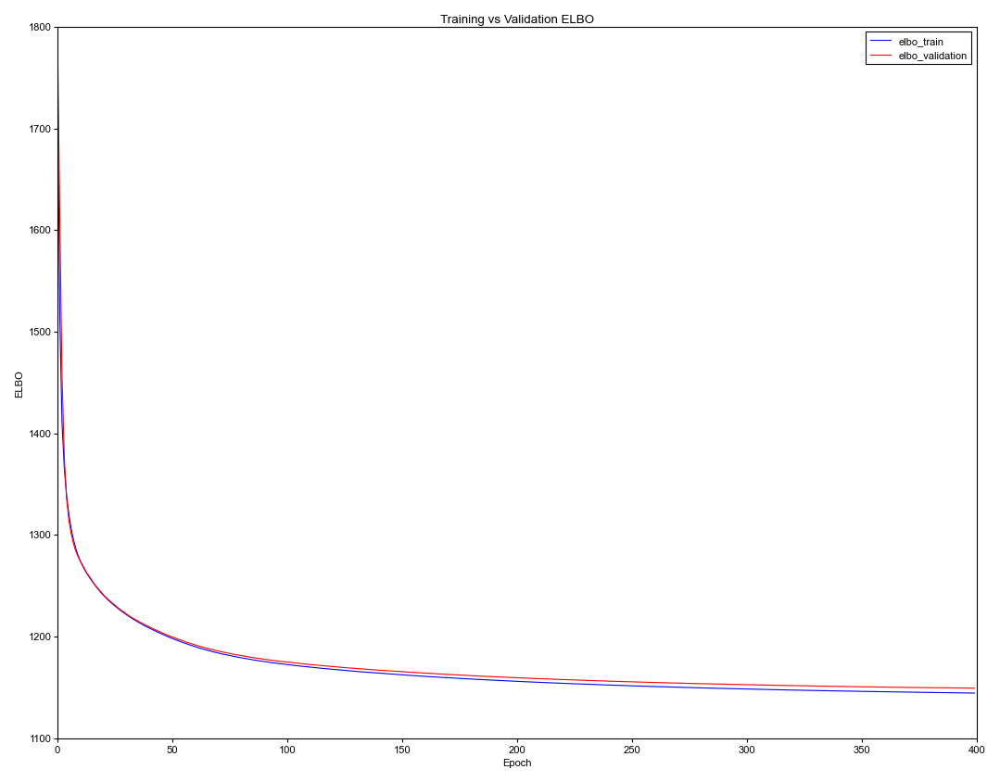

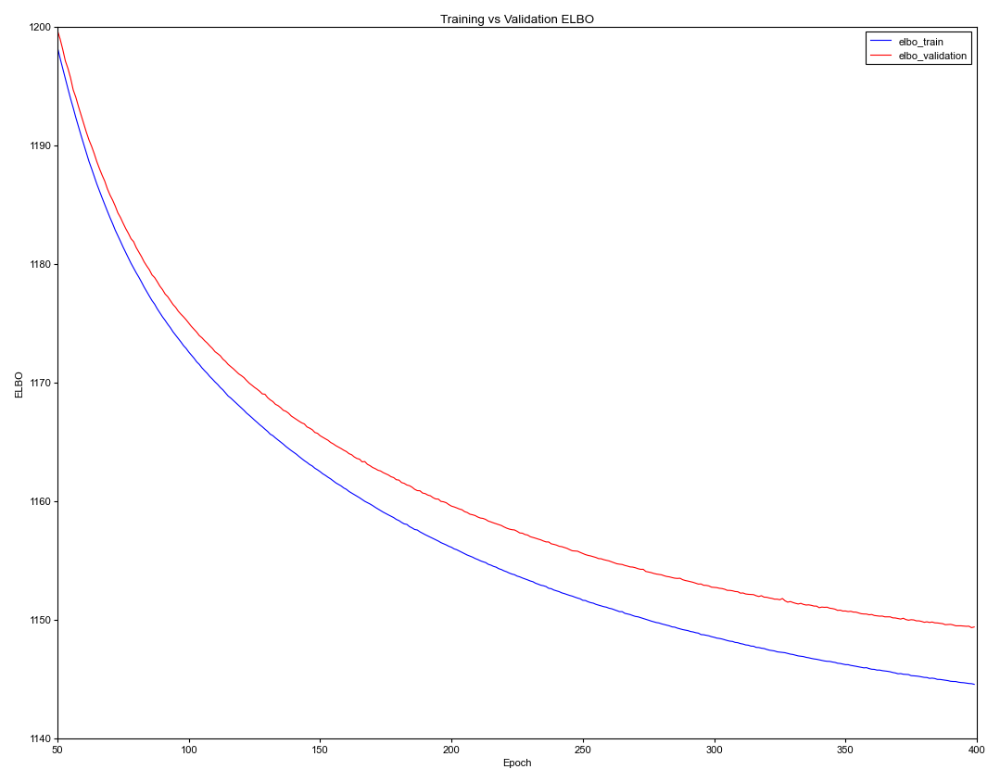

Plotting depth
Plotting age
Plotting annotation
Plotting batch_mixing
Plotting cat_covs


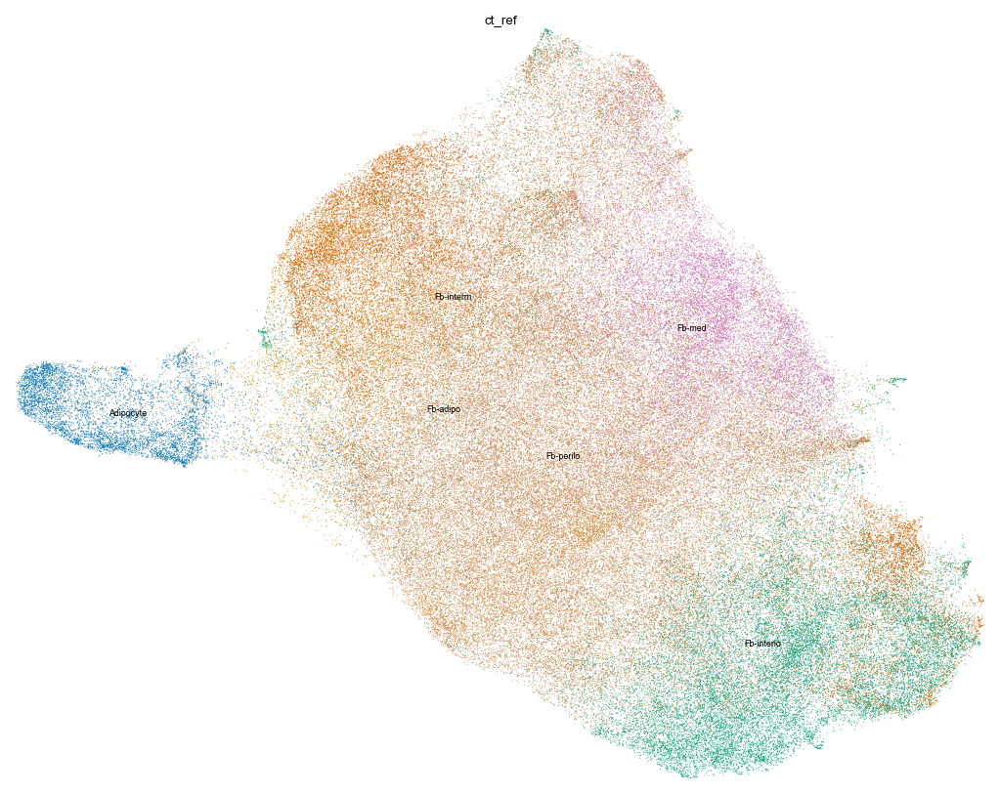

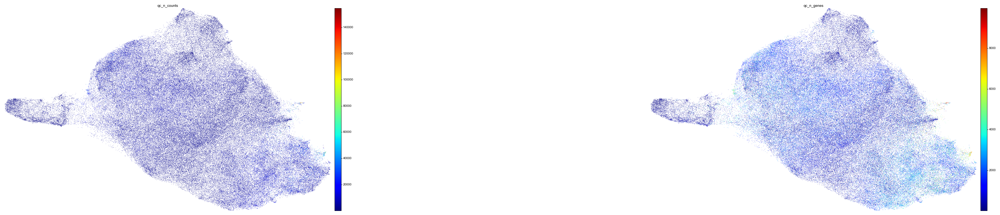

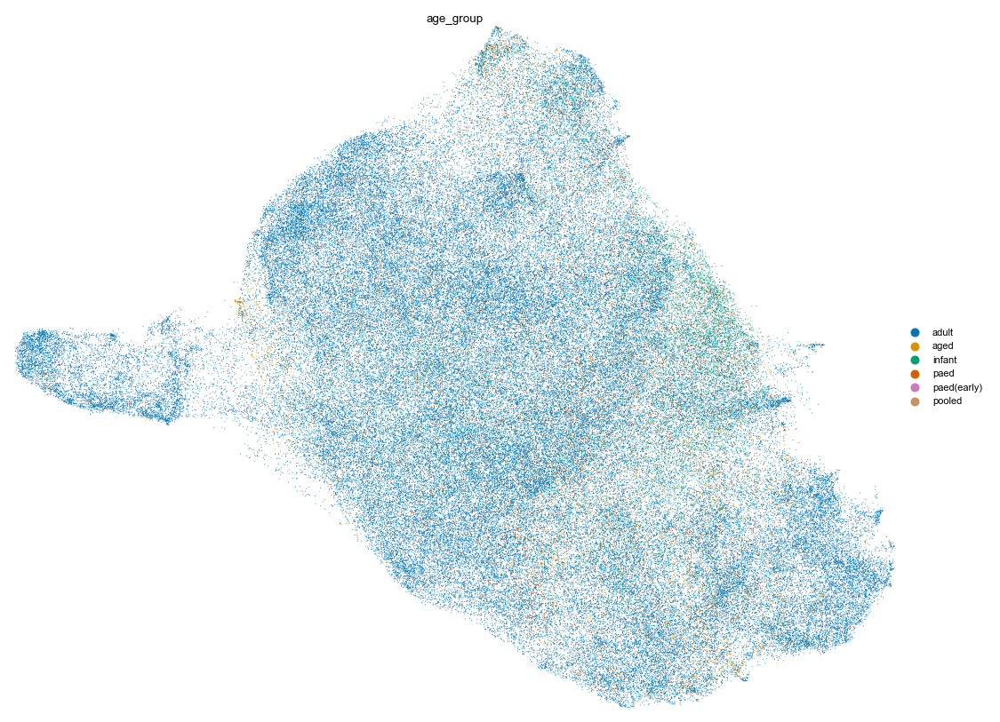

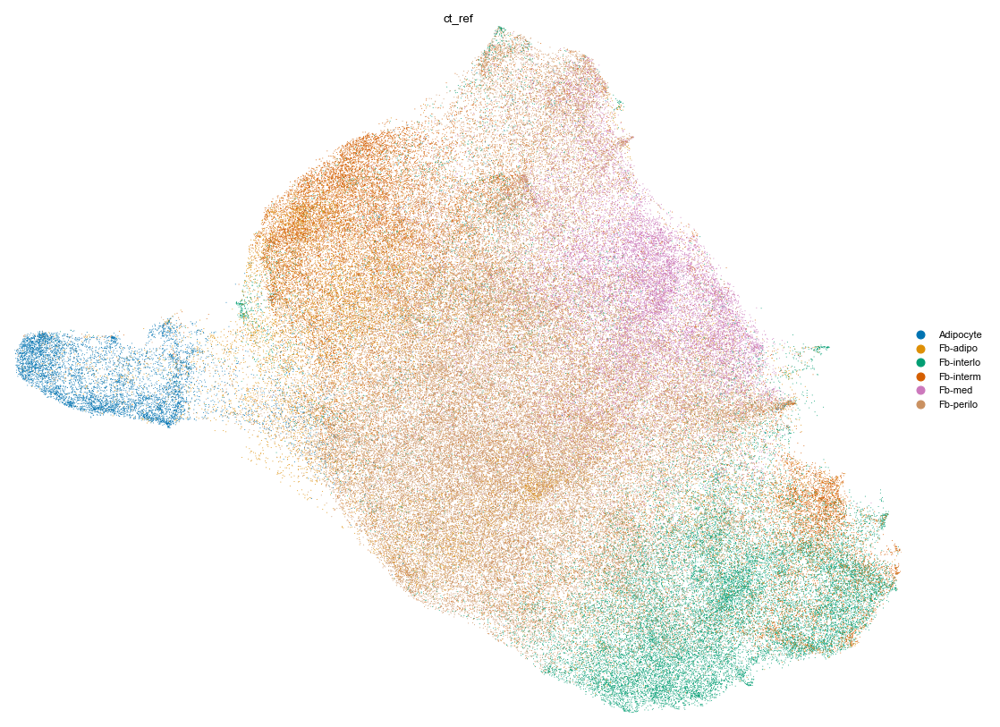

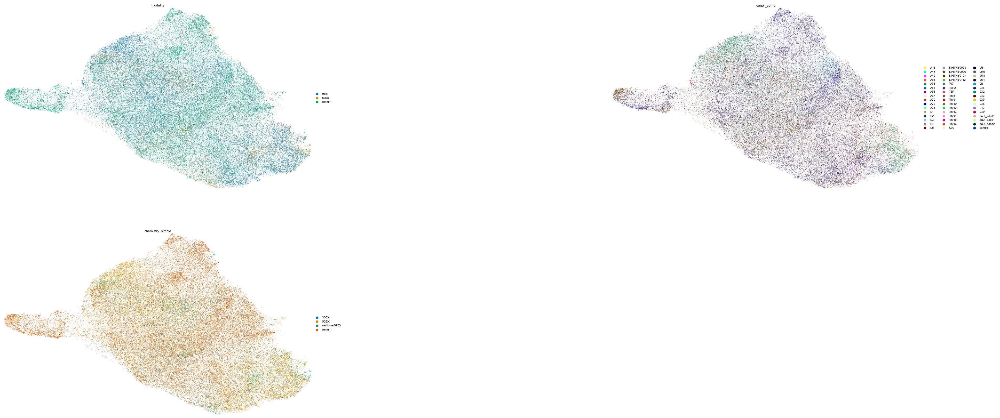

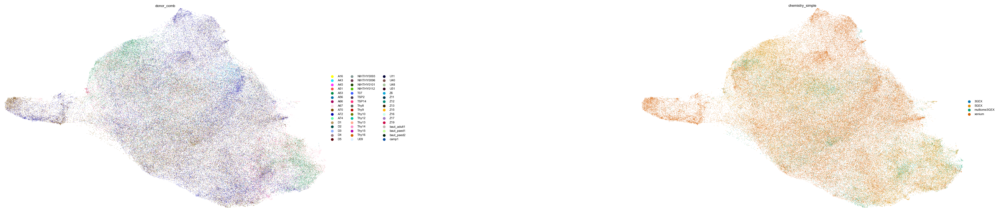

In [20]:
scvi_run = run_scvi(
    adata_all,
    layer_raw='counts',
    include_genes=[], exclude_cc_genes=False, exclude_mt_genes=False, exclude_vdjgenes=False,
    remove_cite=False,
    batch_hv=None, hvg=len(panel_kept),
    batch_scvi=BATCH_SCVI,
    cat_cov_scvi=CAT_COVS,
    cont_cov_scvi=CONT_COVS,
    max_epochs=N_EPOCHS, batch_size=BATCH_SIZE, early_stopping=False,
    plan_kwargs={'lr': LR}, n_layers=N_LAYERS, n_latent=N_LATENT, dispersion=DISPERSION,
    check_val_every_n_epoch=1,
    leiden_clustering=None, col_cell_type='ct_ref',
    covs={'depth': ['qc_n_counts', 'qc_n_genes'],
          'age': ['age_group'],
          'annotation': ['ct_ref'],
          'batch_mixing': ['modality', 'donor_comb', 'chemistry_simple']})

In [21]:
# run_scvi filters **kwargs against the target signatures and DROPS anything misspelled silently.
vae = scvi_run['vae']
adata_int = scvi_run['data']
print('dispersion   :', vae.module.dispersion)
print('n_latent     :', vae.module.n_latent)
print('n_layers     :', len(vae.module.z_encoder.encoder.fc_layers))
print('epochs run   :', len(vae.history['elbo_train']))
print('latent finite:', bool(np.isfinite(adata_int.obsm['X_scVI']).all()))
adata_int

dispersion   : gene-batch
n_latent     : 30
n_layers     : 3
epochs run   : 400
latent finite: True


AnnData object with n_obs × n_vars = 160683 × 4807
    obs: 'donor', 'chemistry_simple', 'age_group', 'modality', 'donor_comb', 'ct_ref', 'qc_n_counts', 'qc_n_genes', 'batch', 'barcode', 'sample', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'predicted_doublet', 'anno_status', 'qc_status', 'taa_l0', 'taa_l1', 'taa_l2', 'taa_l2_v2', 'taa_l3', 'taa_l3_v2', 'taa_l4', 'taa_l5', 'sample_barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap

In [22]:
os.makedirs(MODEL_DIR, exist_ok=True)
vae.save(MODEL_DIR, save_anndata=False, overwrite=True)
adata_int.write_h5ad(OBJ_POST,
                     compression=hdf5plugin.FILTERS["zstd"],
                     compression_opts=hdf5plugin.Zstd(clevel=5).filter_options)
print('wrote', MODEL_DIR)
print('wrote', OBJ_POST)

wrote /nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/models/thyAgeing_scvi_v1_Fb_scell_multiome_xenium_2026-08-11
wrote /nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_Fb_scell_multiome_xenium_scvi_2026-08-11.h5ad


## 11. Integration QC

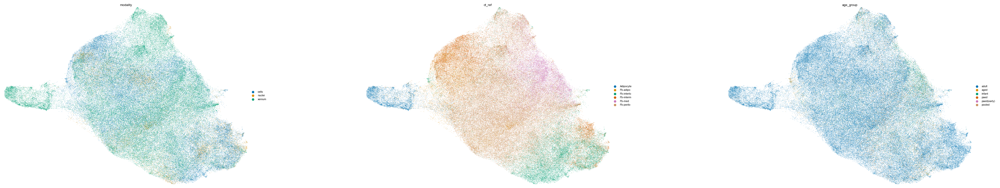

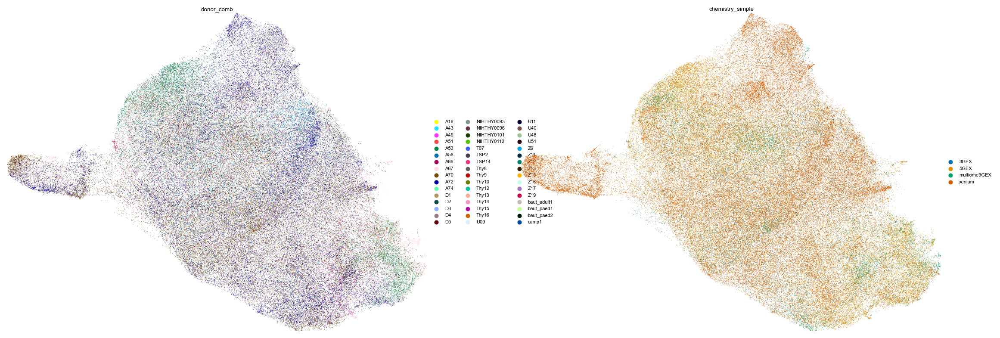

In [23]:
sc.pp.normalize_total(adata_int, target_sum=1e4)
sc.pp.log1p(adata_int)
adata_int.obs['modality'] = pd.Categorical(adata_int.obs['modality'],
                                           categories=['cells', 'nuclei', 'xenium'])
sc.pl.umap(adata_int, color=['modality', 'ct_ref', 'age_group'], frameon=False, ncols=3,
           wspace=0.35)
sc.pl.umap(adata_int, color=['donor_comb', 'chemistry_simple'], frameon=False, ncols=2)

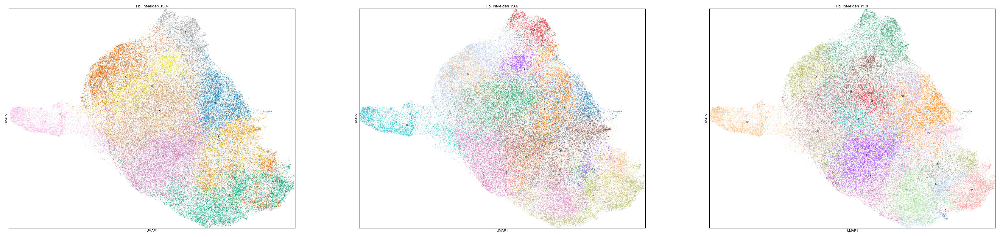

cluster composition by modality (r=0.6):


modality,cells,nuclei,xenium
Fb_int-leiden_r0.6,,,
0,0.446,0.032,0.523
1,0.285,0.056,0.659
2,0.595,0.149,0.255
3,0.056,0.046,0.898
4,0.332,0.024,0.644
5,0.393,0.071,0.536
6,0.373,0.074,0.553
7,0.584,0.206,0.210
8,0.235,0.033,0.732



clusters that are >95% one modality: []

xenium clusters that are >95% one donor: []


In [24]:
# The failure modes: a modality-exclusive island, or a donor-exclusive one (the panel-version tell).
run_leiden(adata_int, resolutions=[0.4, 0.6, 1.0], key_name='Fb_int')

ct = pd.crosstab(adata_int.obs['Fb_int-leiden_r0.6'], adata_int.obs['modality'], normalize='index')
print('cluster composition by modality (r=0.6):')
ct.round(3)
print('\nclusters that are >95% one modality:',
      ct.index[(ct.max(axis=1) > 0.95)].tolist())

ctd = pd.crosstab(adata_int.obs.loc[adata_int.obs['modality'] == 'xenium', 'Fb_int-leiden_r0.6'],
                  adata_int.obs.loc[adata_int.obs['modality'] == 'xenium', 'donor_comb'],
                  normalize='index')
print('\nxenium clusters that are >95% one donor:', ctd.index[(ctd.max(axis=1) > 0.95)].tolist())

--- cells ---


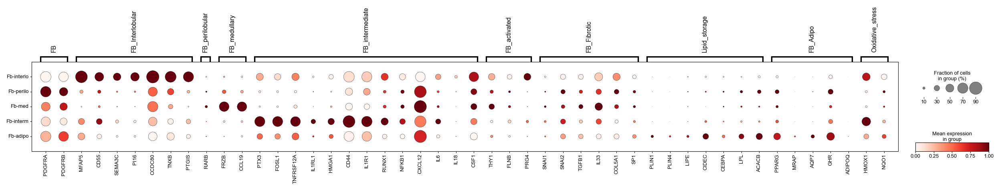

--- nuclei ---


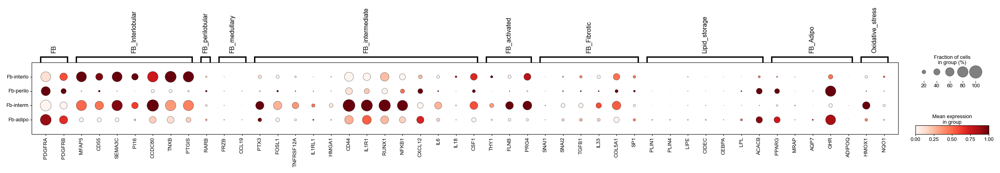

--- xenium ---


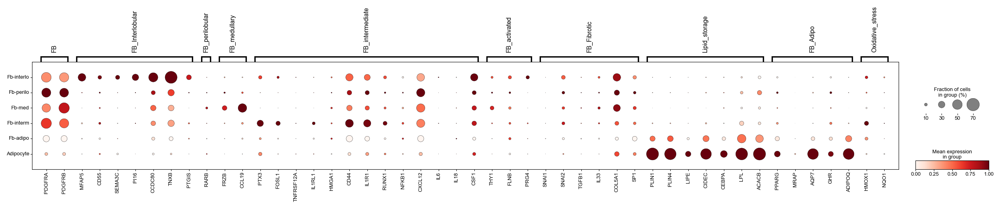

In [25]:
# Does a subtype mean the same thing in each modality? Fb-perilo is the one to watch: it has lost
# COLEC11, and it is the largest Xenium class.
for m in ['cells', 'nuclei', 'xenium']:
    a = adata_int[adata_int.obs['modality'] == m]
    order = [c for c in FB_L3 if c in set(a.obs['ct_ref'])]
    if not order:
        continue
    print(f'--- {m} ---')
    sc.pl.dotplot(a, var_names=FB_markers_x, groupby='ct_ref', categories_order=order,
                  standard_scale='var', mean_only_expressed=True, show=True)

## 12. Label transfer

Reference = scRNAseq **+ multiome**, so `Fb-adipo` is anchored by the modality that actually
recovers adipocyte nuclei. Query = Xenium.

**Circularity caveat:** the incumbent `taa_l3_comb` labels were themselves produced by an earlier
scRNAseq -> Xenium kNN mapping (2025-04, old object, v4/v10 annotation), *and* that mapping predates
the panel-version finding. Old-vs-new agreement below is a sanity check, **not** validation. Any new
claim has to rest on markers or joint-latent neighbour composition.

In [26]:
is_xen = (adata_int.obs['modality'] == 'xenium').values
ref = adata_int[~is_xen]
qry = adata_int[is_xen]
print('reference', ref.n_obs, '| query', qry.n_obs)

knn = weighted_knn_trainer(ref.obsm['X_scVI'], n_neighbors=KNN_K)
pred, unc = weighted_knn_transfer_fast(qry.obsm['X_scVI'], ref.obs, ['ct_ref'], knn,
                                       index=qry.obs_names)
pred.columns = ['knn_pred-taa_l3']
unc.columns  = ['knn_uncert-taa_l3']
lbl = pd.concat([pred, unc], axis=1)
lbl['taa_l3_comb_prev'] = qry.obs['taa_l3_comb'].astype(str).values
lbl['donor'] = qry.obs['donor_comb'].values
lbl.to_csv(LBL_CSV)
print('wrote', LBL_CSV)

lbl['knn_pred-taa_l3'].value_counts()
lbl['knn_uncert-taa_l3'].describe()

reference 85289 | query 75394
wrote /nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/results/Fb_scell_multiome_xenium_knnPred_2026-08-11.csv


knn_pred-taa_l3
Fb-perilo     30258
Fb-interlo    12250
Fb-interm     11465
Fb-adipo      11362
Fb-med        10059
Name: count, dtype: int64

count    7.539400e+04
mean     3.608672e-01
std      1.821220e-01
min     -4.440892e-16
25%      2.332881e-01
50%      3.666784e-01
75%      5.000129e-01
max      7.666774e-01
Name: knn_uncert-taa_l3, dtype: float64

previous label (rows) vs newly transferred (cols):


knn_pred-taa_l3,Fb-adipo,Fb-interlo,Fb-interm,Fb-med,Fb-perilo
taa_l3_comb_prev,,,,,
Adipocyte,6016,161,208,8,696
Fb-adipo,41,31,65,3,47
Fb-interlo,121,3423,445,88,280
Fb-interm,1297,1285,4177,271,1490
Fb-med,312,594,1142,5821,1731
Fb-perilo,3575,6756,5428,3868,26014



overall agreement with the incumbent labels: 52.4%
(a sanity check, not validation -- see the caveat above)


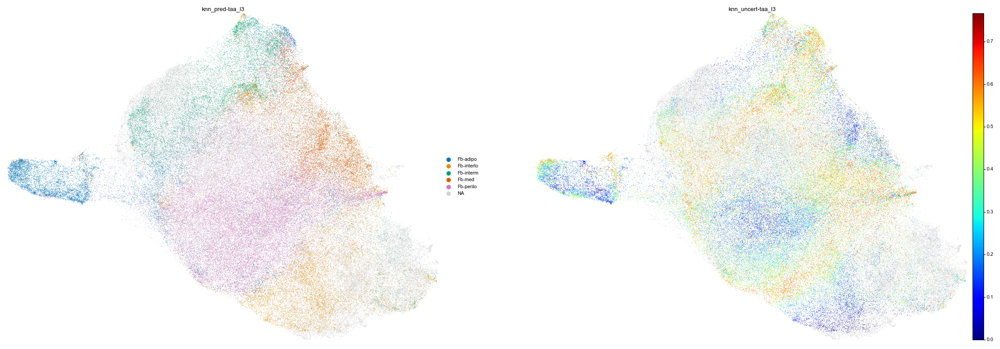

In [27]:
xt = pd.crosstab(lbl['taa_l3_comb_prev'], lbl['knn_pred-taa_l3'])
print('previous label (rows) vs newly transferred (cols):')
xt
agree = float((lbl['taa_l3_comb_prev'] == lbl['knn_pred-taa_l3']).mean())
print(f'\noverall agreement with the incumbent labels: {agree:.1%}')
print('(a sanity check, not validation -- see the caveat above)')

# dtype-safe: build the columns as object / float from the start rather than assigning strings
# into a float column (pandas 3 will raise on that, and anndata cannot write the result)
adata_int.obs['knn_pred-taa_l3'] = pd.Series(
    lbl['knn_pred-taa_l3'], index=adata_int.obs_names, dtype='object').astype('category')
adata_int.obs['knn_uncert-taa_l3'] = pd.Series(
    lbl['knn_uncert-taa_l3'], index=adata_int.obs_names, dtype='float64')
sc.pl.umap(adata_int, color=['knn_pred-taa_l3', 'knn_uncert-taa_l3'], frameon=False, ncols=2)

Uncertainty per incumbent class is the number that says how much of this to believe. Given the
marker-coverage table in 6b, `Fb-perilo` is expected to be the worst — it is the class the panel
cannot see.

In [28]:
u = lbl.groupby('taa_l3_comb_prev')['knn_uncert-taa_l3'].describe()[['count', '25%', '50%', '75%']]
print('transfer uncertainty by incumbent Xenium label:')
u.round(3)
print('\ntransfer uncertainty by newly predicted label:')
lbl.groupby('knn_pred-taa_l3')['knn_uncert-taa_l3'].describe()[['count', '25%', '50%', '75%']].round(3)

transfer uncertainty by incumbent Xenium label:


,count,25%,50%,75%
taa_l3_comb_prev,,,,
Adipocyte,7089.0,0.100,0.233,0.400
Fb-adipo,187.0,0.300,0.433,0.533
Fb-interlo,4357.0,0.067,0.200,0.400
Fb-interm,8520.0,0.300,0.433,0.533
Fb-med,9600.0,0.200,0.367,0.500
Fb-perilo,45641.0,0.267,0.400,0.533



transfer uncertainty by newly predicted label:


,count,25%,50%,75%
knn_pred-taa_l3,,,,
Fb-adipo,11362.0,0.167,0.367,0.533
Fb-interlo,12250.0,0.167,0.367,0.500
Fb-interm,11465.0,0.267,0.400,0.533
Fb-med,10059.0,0.200,0.367,0.500
Fb-perilo,30258.0,0.233,0.367,0.500


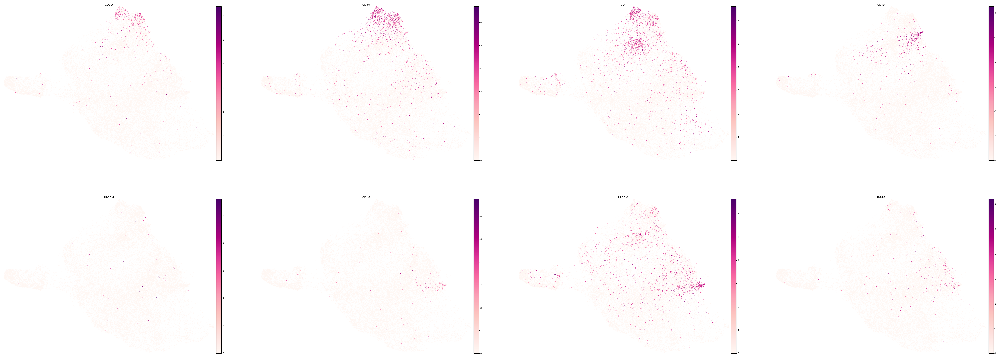

,CD3G,CD8A,CD4,CD19,EPCAM,CDH5,PECAM1,RGS5
pred,,,,,,,,
Fb-adipo,0.067,0.191,0.181,0.036,0.007,0.017,0.193,0.022
Fb-interlo,0.038,0.135,0.311,0.012,0.008,0.025,0.145,0.021
Fb-interm,0.198,0.675,0.800,0.138,0.010,0.010,0.309,0.025
Fb-med,0.095,0.212,0.294,0.241,0.014,0.044,0.364,0.117
Fb-perilo,0.030,0.105,0.141,0.056,0.009,0.028,0.236,0.038


In [29]:
# Xenium segmentation contamination: Fb-called cells carrying another lineage's markers.
if CONTAM_MARKERS_x:
    sc.pl.umap(adata_int[is_xen], color=CONTAM_MARKERS_x, ncols=4, frameon=False, cmap='RdPu')
    contam = pd.DataFrame(
        {g: np.asarray(adata_int[is_xen][:, g].X.todense()).ravel() for g in CONTAM_MARKERS_x},
        index=adata_int.obs_names[is_xen])
    contam['pred'] = lbl['knn_pred-taa_l3']
    contam.groupby('pred').mean().round(3)

## 13. The adipocyte axis

The question: are Xenium `Adipocyte`, multiome `FB_adipo` and the scRNAseq `Fb-adipo` endpoint one
state, or three different things that happen to share a name?

Test 1 — neighbour composition. If they are one state, the joint-latent neighbours of a Xenium
`Adipocyte` cell should be enriched for multiome `Fb-adipo` relative to the background modality mix.

Test 2 — the alternative hypothesis. Xenium `Adipocyte` could be a **segmentation artefact**: large
lipid-laden cells over-capturing neighbouring transcripts. That predicts high `volume` and
`qc_n_counts` and an off-axis position, rather than sitting at the `Fb-adipo` end of the staged
adipogenesis programme.

In [30]:
adipo_mask = (lbl['taa_l3_comb_prev'] == 'Adipocyte').values
print('xenium Adipocyte cells:', int(adipo_mask.sum()))

knn_all = weighted_knn_trainer(adata_int.obsm['X_scVI'], n_neighbors=KNN_K + 1)
_, nb = knn_all.kneighbors(X=qry.obsm['X_scVI'][adipo_mask])
nb = nb[:, 1:]                                            # drop self

nb_mod = adata_int.obs['modality'].values.to_numpy()[nb.ravel()]
nb_ct  = adata_int.obs['ct_ref'].astype(str).values[nb.ravel()]
comp = pd.crosstab(pd.Series(nb_mod, name='neighbour_modality'),
                   pd.Series(nb_ct,  name='neighbour_ct_ref'), normalize='all')
print('neighbour composition of xenium Adipocyte cells:')
comp.round(4)

bg = adata_int.obs['modality'].value_counts(normalize=True)
obs_mod = pd.Series(nb_mod).value_counts(normalize=True)
print('\nmodality enrichment vs background:')
(obs_mod / bg).round(2)

xenium Adipocyte cells: 7089
neighbour composition of xenium Adipocyte cells:


neighbour_ct_ref,Adipocyte,Fb-adipo,Fb-interlo,Fb-interm,Fb-med,Fb-perilo
neighbour_modality,,,,,,
cells,0.0000,0.0459,0.0052,0.0080,0.0006,0.0248
nuclei,0.0000,0.0088,0.0003,0.0001,0.0000,0.0003
xenium,0.8209,0.0048,0.0025,0.0178,0.0011,0.0589



modality enrichment vs background:


xenium    1.93
cells     0.19
nuclei    0.10
Name: proportion, dtype: float64

mean staged-adipogenesis score by modality x label:


adipo_progenitors  adipo_committed  adipo_preadipocytes  \
modality ct_ref                                                                
cells    Fb-adipo                0.113           -0.100                0.293   
         Fb-interlo              0.664           -0.061               -0.259   
         Fb-interm               0.054           -0.042               -0.068   
         Fb-med                  0.076           -0.051               -0.095   
         Fb-perilo               0.232           -0.065                0.036   
nuclei   Fb-adipo                0.158            0.321                0.134   
         Fb-interlo              0.521            0.364               -0.327   
         Fb-interm               0.448            0.533               -0.347   
         Fb-perilo              -0.073            0.188                0.093   
xenium   Adipocyte              -0.216           -0.052                1.513   
         Fb-adipo               -0.086            0.026                0.829   
         Fb-interlo              0.534            0.025               -0.083   
         Fb-interm               0.206            0.002                0.155   
         Fb-med                  0.228            0.009               -0.095   
         Fb-perilo               0.285            0.001                0.055   

                     adipo_mature adipocytes  adipo_mature subtypes  
modality ct_ref                                                      
cells    Fb-adipo                      0.022                  0.018  
         Fb-interlo                   -0.210                 -0.088  
         Fb-interm                    -0.140                 -0.029  
         Fb-med                       -0.178                 -0.150  
         Fb-perilo                    -0.167                 -0.083  
nuclei   Fb-adipo                     -0.184                 -0.000  
         Fb-interlo                   -0.239                 -0.058  
         Fb-interm                    -0.274                  0.066  
         Fb-perilo                    -0.169                 -0.033  
xenium   Adipocyte                     2.810                  1.096  
         Fb-adipo                      0.745                  0.319  
         Fb-interlo                   -0.096                 -0.067  
         Fb-interm                    -0.055                 -0.007  
         Fb-med                       -0.155                 -0.107  
         Fb-perilo                    -0.062                 -0.045

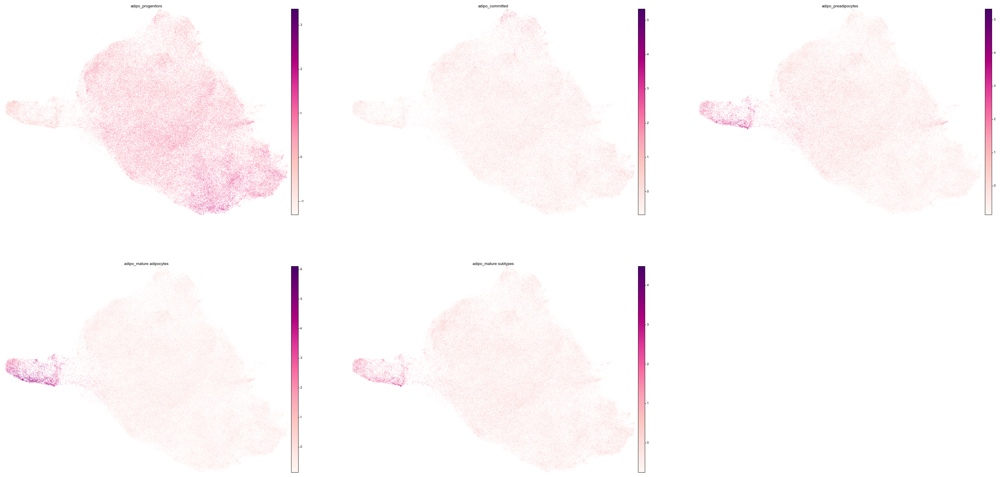

In [31]:
# Staged adipogenesis, scored per modality on the shared gene space
for stage, gl in adipose_dif_genes_x.items():
    if len(gl) >= 2:
        sc.tl.score_genes(adata_int, gene_list=gl, score_name=f'adipo_{stage}')
score_cols = [f'adipo_{s}' for s in adipose_dif_genes_x if f'adipo_{s}' in adata_int.obs]

grp = adata_int.obs.copy()
grp['label'] = np.where(grp['modality'] == 'xenium',
                        grp['knn_pred-taa_l3'].astype(str) + ' (xen:' + grp['ct_ref'].astype(str) + ')',
                        grp['ct_ref'].astype(str))
tbl = grp.groupby(['modality', 'ct_ref'], observed=True)[score_cols].mean()
print('mean staged-adipogenesis score by modality x label:')
tbl.round(3)
sc.pl.umap(adata_int, color=score_cols, ncols=3, frameon=False, cmap='RdPu')

volume / depth of Adipocyte vs other Fb cells (Xenium only):


is_adipo              False    True 
volume      count  68305.00  7089.00
            mean      31.94    45.20
            std       18.05    35.87
            min        2.25     4.75
            25%       19.25    24.25
            50%       28.25    35.50
            75%       40.25    53.75
            max      280.00   545.25
qc_n_counts count  68305.00  7089.00
            mean     240.80   275.00
            std      183.66   281.66
            min       29.00    30.00
            25%      105.00    89.00
            50%      194.00   180.00
            75%      325.00   362.00
            max     2354.00  3480.00
qc_n_genes  count  68305.00  7089.00
            mean     192.35   190.32
            std      125.69   150.42
            min       29.00    30.00
            25%       94.00    76.00
            50%      166.00   144.00
            75%      262.00   261.00
            max     1118.00  1261.00

(array([8.38590232e-04, 2.93506581e-03, 1.67718046e-03, 1.25788535e-03,
        2.09647558e-03, 3.35436093e-03, 6.28942674e-03, 1.00630828e-02,
        7.96660720e-03, 2.89313630e-02, 1.59332144e-02, 4.82189383e-02,
        6.79258088e-02, 6.96029892e-02, 1.46753291e-01, 1.20337698e-01,
        2.02100246e-01, 2.43610462e-01, 2.82604908e-01, 3.28727371e-01,
        4.96445417e-01, 5.40890699e-01, 7.71503013e-01, 6.95191302e-01,
        1.10400404e+00, 9.58089340e-01, 1.21889090e+00, 1.42560339e+00,
        1.42434551e+00, 1.66795597e+00, 1.55474629e+00, 1.72665729e+00,
        1.73504319e+00, 1.73126953e+00, 1.61847915e+00, 1.40505793e+00,
        1.40715441e+00, 1.19289460e+00, 9.89117178e-01, 7.98337901e-01,
        6.72130071e-01, 4.96445417e-01, 4.33131855e-01, 2.95183762e-01,
        2.10066853e-01, 1.63105800e-01, 1.04404484e-01, 7.75695964e-02,
        4.52838725e-02, 3.06085435e-02, 2.51577070e-02, 1.42560339e-02,
        7.96660720e-03, 4.61224627e-03, 2.93506581e-03, 1.257885

(array([0.00410884, 0.01643538, 0.02876191, 0.01232653, 0.02054422,
        0.04519729, 0.06574151, 0.05752382, 0.10272111, 0.08628573,
        0.17668031, 0.22598645, 0.27529258, 0.37801369, 0.54236747,
        0.60400014, 0.69028587, 0.80122467, 1.23265334, 1.17102067,
        1.16280298, 1.70517045, 1.52438129, 1.35180983, 1.65175547,
        1.67229969, 1.4422044 , 1.36002752, 1.42166018, 1.24497987,
        1.09295263, 1.08062609, 1.02721111, 0.69028587, 0.66152396,
        0.61632667, 0.4437552 , 0.34103409, 0.40266676, 0.33692525,
        0.28351027, 0.2218776 , 0.1479184 , 0.11504764, 0.16024493,
        0.08217689, 0.0739592 , 0.08628573, 0.0369796 , 0.04930613,
        0.02054422, 0.02054422, 0.01643538, 0.02465307, 0.00821769,
        0.        , 0.        , 0.00410884, 0.00410884, 0.00410884]),
 array([0.67669361, 0.71102531, 0.74535701, 0.77968871, 0.81402041,
        0.84835212, 0.88268382, 0.91701552, 0.95134722, 0.98567892,
        1.02001062, 1.05434232, 1.08867402, 1.

Text(0.5, 0, 'log10 volume')

...

(array([0.10249442, 0.26238572, 0.39767836, 0.35258081, 0.45917501,
        0.5862681 , 0.50017278, 0.59036787, 0.7092614 , 0.66826364,
        0.68056297, 0.75025917, 0.75845873, 0.67236341, 0.88145203,
        0.75435895, 0.81175583, 0.75845873, 0.91425025, 0.76665828,
        0.78715717, 0.86095315, 0.86505293, 0.75845873, 0.88555181,
        0.82815493, 0.80765605, 0.78715717, 0.91425025, 0.81175583,
        0.70106185, 0.82405516, 0.78715717, 0.59856743, 0.71336118,
        0.67646319, 0.66416386, 0.48787345, 0.51657189, 0.43867613,
        0.38947881, 0.28698438, 0.24188684, 0.20088907, 0.15579152,
        0.15169175, 0.13119286, 0.07789576, 0.12709308, 0.06149665,
        0.02869844, 0.03689799, 0.02049888, 0.02049888, 0.00409978,
        0.02049888, 0.00409978, 0.00819955, 0.        , 0.00409978]),
 array([1.47712125, 1.51152889, 1.54593652, 1.58034415, 1.61475179,
        1.64915942, 1.68356705, 1.71797469, 1.75238232, 1.78678995,
        1.82119759, 1.85560522, 1.89001285, 1.

Text(0.5, 0, 'log10 qc_n_counts')

(array([1.17967718e-01, 2.69719619e-01, 2.60858194e-01, 2.82457917e-01,
        4.23686876e-01, 2.78027205e-01, 4.46394277e-01, 4.31994462e-01,
        4.54148024e-01, 4.43625082e-01, 4.46394277e-01, 6.11438315e-01,
        4.23686876e-01, 5.88177075e-01, 7.46575044e-01, 5.99253856e-01,
        7.21652287e-01, 7.57097986e-01, 8.98880784e-01, 6.68483738e-01,
        9.81956642e-01, 8.17466443e-01, 9.92479584e-01, 9.58141563e-01,
        1.10269356e+00, 1.21179985e+00, 1.15918514e+00, 1.08718606e+00,
        1.20072307e+00, 1.28933732e+00, 1.20847682e+00, 1.25001474e+00,
        1.33585980e+00, 1.20847682e+00, 1.31204472e+00, 1.20127691e+00,
        1.18798477e+00, 1.18300022e+00, 1.07112473e+00, 9.76972091e-01,
        9.36541840e-01, 8.66204280e-01, 7.67620928e-01, 6.04792247e-01,
        4.55255702e-01, 4.18148486e-01, 3.10149870e-01, 2.58088999e-01,
        1.85536083e-01, 1.30706017e-01, 9.91371906e-02, 6.86760427e-02,
        3.93225728e-02, 3.54456994e-02, 1.77228497e-02, 1.606133

(array([0.37012399, 0.36491097, 0.58385755, 0.43268015, 0.41704111,
        0.55257947, 0.68290482, 0.58907057, 0.65162674, 0.54736646,
        0.91227743, 0.84972126, 0.77152605, 0.72460893, 0.83929523,
        0.84972126, 0.82365619, 0.90706442, 0.87057332, 0.84450825,
        0.96440757, 0.92270346, 0.83408222, 0.88621236, 1.06345483,
        0.99568565, 0.96440757, 0.96440757, 1.00089867, 1.03217675,
        0.96440757, 0.94876853, 0.87578633, 0.93312948, 1.06345483,
        0.79237811, 0.94355551, 0.81844318, 0.79237811, 0.78195208,
        0.76631304, 0.6776918 , 0.66205276, 0.57343153, 0.34405892,
        0.40661508, 0.28671576, 0.27628974, 0.20852056, 0.16681644,
        0.16160343, 0.09383425, 0.07819521, 0.05213014, 0.02606507,
        0.01563904, 0.02085206, 0.00521301, 0.        , 0.00521301]),
 array([1.47712125, 1.50418115, 1.53124105, 1.55830095, 1.58536084,
        1.61242074, 1.63948064, 1.66654054, 1.69360043, 1.72066033,
        1.74772023, 1.77478012, 1.80184002, 1.

Text(0.5, 0, 'log10 qc_n_genes')

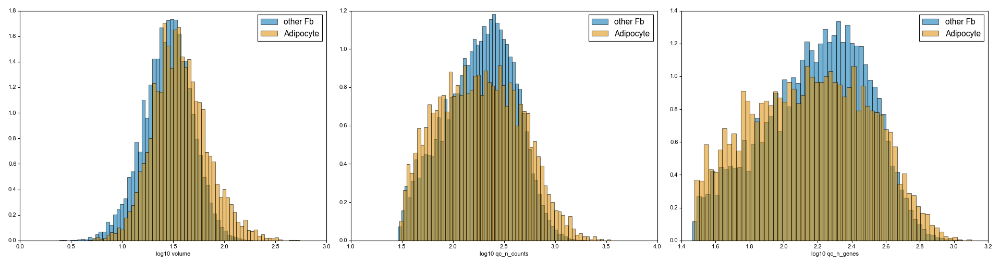

In [32]:
# Test 2: is the Xenium Adipocyte call a segmentation artefact?
xo = adata_int.obs[is_xen].copy()
xo['is_adipo'] = adipo_mask
print('volume / depth of Adipocyte vs other Fb cells (Xenium only):')
xo.groupby('is_adipo')[['volume', 'qc_n_counts', 'qc_n_genes']].describe().T.round(2)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, c in zip(axes, ['volume', 'qc_n_counts', 'qc_n_genes']):
    for v, lab in [(False, 'other Fb'), (True, 'Adipocyte')]:
        d = xo.loc[xo['is_adipo'] == v, c].dropna()
        ax.hist(np.log10(d[d > 0]), bins=60, alpha=0.55, density=True, label=lab)
    ax.set_xlabel(f'log10 {c}'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [33]:
# Donor-matched composition: the 6 donors shared between Xenium and the scRNAseq atlas.
shared = (set(adata_int.obs.loc[adata_int.obs['modality'] == 'xenium', 'donor_comb'])
          & set(adata_int.obs.loc[adata_int.obs['modality'] != 'xenium', 'donor_comb']))
print('donors shared across modalities:', sorted(shared))

sub = adata_int.obs[adata_int.obs['donor_comb'].isin(shared)]
comp_d = (pd.crosstab([sub['donor_comb'], sub['modality']], sub['ct_ref'], normalize='index')
          .round(3))
comp_d

donors shared across modalities: ['A67', 'A70', 'A72', 'U48', 'Z16', 'Z17']


ct_ref               Adipocyte  Fb-adipo  Fb-interlo  Fb-interm  Fb-med  \
donor_comb modality                                                       
A67        cells         0.000     0.018       0.416      0.257   0.030   
           nuclei        0.000     0.493       0.094      0.274   0.000   
           xenium        0.075     0.002       0.050      0.328   0.035   
A70        cells         0.000     0.169       0.303      0.072   0.043   
           nuclei        0.000     0.592       0.182      0.082   0.000   
           xenium        0.157     0.002       0.043      0.020   0.049   
A72        cells         0.000     0.011       0.776      0.045   0.027   
           nuclei        0.000     0.368       0.467      0.123   0.000   
           xenium        0.091     0.004       0.071      0.132   0.169   
U48        cells         0.000     0.000       0.043      0.000   0.435   
           nuclei        0.000     0.750       0.250      0.000   0.000   
           xenium        0.001     0.000       0.031      0.012   0.359   
Z16        cells         0.000     0.000       0.083      0.000   0.500   
           xenium        0.007     0.000       0.081      0.017   0.208   
Z17        cells         0.000     0.023       0.176      0.011   0.221   
           nuclei        0.000     0.821       0.107      0.071   0.000   
           xenium        0.014     0.001       0.097      0.023   0.216   

ct_ref               Fb-perilo  
donor_comb modality             
A67        cells         0.279  
           nuclei        0.139  
           xenium        0.509  
A70        cells         0.413  
           nuclei        0.144  
           xenium        0.729  
A72        cells         0.141  
           nuclei        0.042  
           xenium        0.534  
U48        cells         0.522  
           nuclei        0.000  
           xenium        0.597  
Z16        cells         0.417  
           xenium        0.688  
Z17        cells         0.569  
           nuclei        0.000  
           xenium        0.649

In [34]:
# The transferred-label columns are object(str + NaN); sanitise before the write.
sanitize_for_write(adata_int, inplace=True)
adata_int.write_h5ad(OBJ_POST,
                     compression=hdf5plugin.FILTERS["zstd"],
                     compression_opts=hdf5plugin.Zstd(clevel=5).filter_options)
print('re-wrote with leiden / scores / transferred labels:', OBJ_POST)
print('label CSV :', LBL_CSV)
print('gene space:', GENE_CSV)
print('model     :', MODEL_DIR)

sanitize_for_write: nothing to fix


AnnData object with n_obs × n_vars = 160683 × 4807
    obs: 'donor', 'chemistry_simple', 'age_group', 'modality', 'donor_comb', 'ct_ref', 'qc_n_counts', 'qc_n_genes', 'batch', 'barcode', 'sample', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'predicted_doublet', 'anno_status', 'qc_status', 'taa_l0', 'taa_l1', 'taa_l2', 'taa_l2_v2', 'taa_l3', 'taa_l3_v2', 'taa_l4', 'taa_l5', 'sample_barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap

re-wrote with leiden / scores / transferred labels: /nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_Fb_scell_multiome_xenium_scvi_2026-08-11.h5ad
label CSV : /nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/results/Fb_scell_multiome_xenium_knnPred_2026-08-11.csv
gene space: /nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/results/Fb_scell_multiome_xenium_geneSpace_2026-08-11.csv
model     : /nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/models/thyAgeing_scvi_v1_Fb_scell_multiome_xenium_2026-08-11
